# Week 06：逻辑回归

## 逻辑回归从零实现——基于糖尿病数据的二分类

### 1. 实验目的

本实验使用糖尿病数据集完成二分类任务，并使用 NumPy 从零实现逻辑回归（Logistic Regression）算法。

主要实验内容：

1. 理解逻辑回归的基本原理；
2. 实现 Sigmoid 函数；
3. 实现二分类交叉熵损失函数；
4. 使用梯度下降训练逻辑回归模型；
5. 分析模型训练过程中 Loss 的变化；
6. 使用 Accuracy、混淆矩阵、Precision、Recall 和 F1-score 评价模型；
7. 与 Scikit-learn 的 LogisticRegression 进行对比。

### 2. 导入实验所需库

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression

### 3. 数据集加载与基本分析

本实验使用 Pima Indians Diabetes 数据集进行糖尿病二分类实验。

数据集包含多个与糖尿病诊断相关的特征，分类标签 `Outcome` 表示是否患有糖尿病：

- `Outcome = 0`：未患糖尿病
- `Outcome = 1`：患有糖尿病

首先读取数据集，并观察数据规模、特征以及类别分布。

In [2]:
column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv("diabetes.csv", names=column_names)

print("数据集形状：", df.shape)
print("\n前 5 条数据：")
display(df.head())

数据集形状： (768, 9)

前 5 条数据：


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# 查看数据集基本信息
print("数据集基本信息：")
df.info()

print("\n缺失值数量：")
print(df.isnull().sum())

print("\n标签分布：")
print(df["Outcome"].value_counts())

print("\n标签比例：")
print(df["Outcome"].value_counts(normalize=True))

数据集基本信息：
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

缺失值数量：
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                     

### 4. 数据预处理

虽然数据集中不存在 Pandas 可以直接识别的缺失值，但部分医学指标中存在数值为 0 的情况。

对于 Glucose、BloodPressure、SkinThickness、Insulin 和 BMI 等指标，数值为 0 通常不能表示正常的实际测量结果，因此需要进一步检查这些特征中的 0 值数量。

In [4]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("各特征中 0 值的数量：")

for column in zero_columns:
    zero_count = (df[column] == 0).sum()
    zero_ratio = zero_count / len(df)

    print(
        f"{column}: {zero_count} 个，"
        f"占比 {zero_ratio:.2%}"
    )

各特征中 0 值的数量：
Glucose: 5 个，占比 0.65%
BloodPressure: 35 个，占比 4.56%
SkinThickness: 227 个，占比 29.56%
Insulin: 374 个，占比 48.70%
BMI: 11 个，占比 1.43%


In [5]:
# 分离特征和标签
X = df.drop("Outcome", axis=1).copy()
y = df["Outcome"].copy()

# 将部分医学指标中的异常 0 值转换为 NaN
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

print("转换后的缺失值数量：")
print(X.isnull().sum())

转换后的缺失值数量：
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [6]:
# 按照 8:2 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("训练集特征形状：", X_train.shape)
print("测试集特征形状：", X_test.shape)

print("\n训练集标签分布：")
print(y_train.value_counts())

print("\n测试集标签分布：")
print(y_test.value_counts())

训练集特征形状： (614, 8)
测试集特征形状： (154, 8)

训练集标签分布：
Outcome
0    400
1    214
Name: count, dtype: int64

测试集标签分布：
Outcome
0    100
1     54
Name: count, dtype: int64


In [7]:
# 只使用训练集计算各特征的中位数
train_medians = X_train.median()

# 使用训练集的中位数填充训练集和测试集
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("填充后训练集缺失值数量：", X_train.isnull().sum().sum())
print("填充后测试集缺失值数量：", X_test.isnull().sum().sum())

print("\n用于填充的训练集特征中位数：")
print(train_medians[zero_columns])

填充后训练集缺失值数量： 0
填充后测试集缺失值数量： 0

用于填充的训练集特征中位数：
Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.4
dtype: float64


### 5. 特征标准化

由于不同特征的数值范围存在较大差异，例如 Insulin 的数值可能达到数百，而 DiabetesPedigreeFunction 通常小于几，因此需要对特征进行标准化。

本实验使用 StandardScaler 对特征进行标准化，使各特征的均值接近 0、标准差接近 1。

为了避免数据泄漏，标准化器只在训练集上进行拟合，再使用相同的标准化参数转换训练集和测试集。

In [8]:
# 创建标准化器
scaler = StandardScaler()

# 只使用训练集拟合标准化器
X_train_scaled = scaler.fit_transform(X_train)

# 使用训练集得到的参数转换测试集
X_test_scaled = scaler.transform(X_test)

print("标准化后训练集形状：", X_train_scaled.shape)
print("标准化后测试集形状：", X_test_scaled.shape)

print("\n训练集各特征标准化后的均值：")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\n训练集各特征标准化后的标准差：")
print(np.round(X_train_scaled.std(axis=0), 4))

标准化后训练集形状： (614, 8)
标准化后测试集形状： (154, 8)

训练集各特征标准化后的均值：
[-0. -0.  0. -0. -0.  0. -0. -0.]

训练集各特征标准化后的标准差：
[1. 1. 1. 1. 1. 1. 1. 1.]


### 6. 从零实现逻辑回归

逻辑回归首先通过线性模型计算：

$$
z = w^T x + b
$$

然后使用 Sigmoid 函数将线性模型的输出映射到 `(0, 1)` 区间：

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Sigmoid 的输出可以解释为样本属于正类 `y=1` 的概率。

当预测概率大于等于 0.5 时，将样本预测为正类；否则预测为负类。

In [9]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [10]:
test_z = np.array([-2, -1, 0, 1, 2])

print("输入：", test_z)
print("Sigmoid 输出：", sigmoid(test_z))

输入： [-2 -1  0  1  2]
Sigmoid 输出： [0.11920292 0.26894142 0.5        0.73105858 0.88079708]


### 7. 二分类交叉熵损失

逻辑回归通常使用二分类交叉熵（Binary Cross-Entropy）衡量预测结果与真实标签之间的差异：

$$
L=-\frac{1}{m}\sum_{i=1}^{m}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
$$

其中：

- `y_i`：样本的真实标签，取值为 0 或 1；
- `p_i`：模型预测样本属于正类的概率；
- `m`：样本数量。

当模型给真实类别预测的概率越低时，交叉熵损失越大。

In [11]:
def binary_cross_entropy(y, p):
    # 防止 log(0) 导致数值计算错误
    epsilon = 1e-15
    p = np.clip(p, epsilon, 1 - epsilon)

    loss = -np.mean(
        y * np.log(p) + (1 - y) * np.log(1 - p)
    )

    return loss

In [12]:
y_test_example = np.array([1, 0])
p_test_example = np.array([0.9, 0.1])

print("交叉熵损失：", binary_cross_entropy(y_test_example, p_test_example))

交叉熵损失： 0.10536051565782628


### 8. 从零实现逻辑回归模型

本实验使用梯度下降法训练逻辑回归模型。

模型首先计算线性输出：

$$
z=Xw+b
$$

再通过 Sigmoid 函数得到预测概率：

$$
p=\sigma(z)
$$

随后根据预测概率与真实标签计算梯度，并更新模型参数 $w$ 和 $b$。

训练过程中记录每一轮的交叉熵损失，用于观察模型是否逐渐收敛。

In [13]:
class MyLogisticRegression:
    def __init__(self, learning_rate=0.1, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y):
        # 样本数量和特征数量
        n_samples, n_features = X.shape

        # 初始化参数
        self.w = np.zeros(n_features)
        self.b = 0.0

        # 转换为 NumPy 数组
        y = np.asarray(y)

        # 梯度下降
        for epoch in range(self.epochs):

            # 1. 计算线性输出
            z = X @ self.w + self.b

            # 2. 使用 Sigmoid 得到预测概率
            p = sigmoid(z)

            # 3. 计算交叉熵损失
            loss = binary_cross_entropy(y, p)
            self.loss_history.append(loss)

            # 4. 计算梯度
            dw = (1 / n_samples) * (X.T @ (p - y))
            db = (1 / n_samples) * np.sum(p - y)

            # 5. 更新参数
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        z = X @ self.w + self.b
        return sigmoid(z)

    def predict(self, X):
        probabilities = self.predict_proba(X)

        # 以 0.5 作为分类阈值
        return (probabilities >= 0.5).astype(int)

In [15]:
my_model = MyLogisticRegression(
    learning_rate=0.1,
    epochs=1000
)

my_model.fit(X_train_scaled, y_train)

print("训练完成！")
print("初始 Loss：", my_model.loss_history[0])
print("最终 Loss：", my_model.loss_history[-1])
print("偏置 b：", my_model.b)
print("权重 w：")
print(my_model.w)

训练完成！
初始 Loss： 0.6931471805599453
最终 Loss： 0.4530769300728527
偏置 b： -0.8767202236985615
权重 w：
[ 0.3849388   1.20541007 -0.04997751  0.02283097 -0.07521196  0.70385027
  0.23644171  0.14668185]


### 9. 模型训练过程分析

为了观察梯度下降过程中模型是否逐渐收敛，绘制每轮训练的交叉熵损失曲线。

如果 Loss 随着训练轮数增加逐渐下降并趋于稳定，说明梯度下降能够有效优化逻辑回归模型。

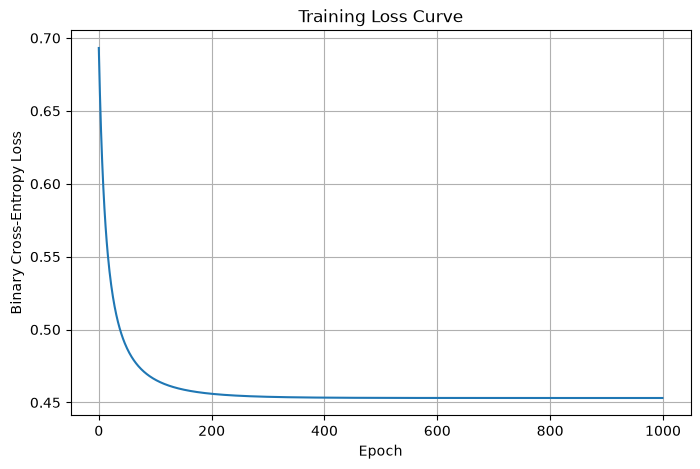

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(my_model.loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss Curve")

plt.grid(True)
plt.show()

### 10. 手写逻辑回归模型测试

使用训练完成的逻辑回归模型对测试集进行预测。

模型首先输出样本属于正类的概率，再以 0.5 作为分类阈值：

- 预测概率 ≥ 0.5：预测为 1；
- 预测概率 < 0.5：预测为 0。

最后使用 Accuracy、混淆矩阵以及 Precision、Recall、F1-score 对模型进行评价。

In [17]:
# 在测试集上预测
y_prob = my_model.predict_proba(X_test_scaled)
y_pred = my_model.predict(X_test_scaled)

# 计算准确率
accuracy = accuracy_score(y_test, y_pred)

print(f"手写逻辑回归测试集 Accuracy：{accuracy:.4f}")
print(f"手写逻辑回归测试集 Accuracy：{accuracy * 100:.2f}%")

print("\n前 10 个样本的预测概率：")
print(np.round(y_prob[:10], 4))

print("\n前 10 个样本的预测结果：")
print(y_pred[:10])

print("\n前 10 个样本的真实标签：")
print(y_test.to_numpy()[:10])

手写逻辑回归测试集 Accuracy：0.7078
手写逻辑回归测试集 Accuracy：70.78%

前 10 个样本的预测概率：
[0.6151 0.1152 0.2918 0.2495 0.0321 0.1674 0.4873 0.9274 0.0798 0.8425]

前 10 个样本的预测结果：
[1 0 0 0 0 0 0 1 0 1]

前 10 个样本的真实标签：
[0 0 0 1 0 0 1 1 0 0]


In [18]:
print("混淆矩阵：")
print(confusion_matrix(y_test, y_pred))

print("\n分类报告：")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

混淆矩阵：
[[82 18]
 [27 27]]

分类报告：
              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



### 11. 与 Scikit-learn 逻辑回归模型对比

为了验证手写逻辑回归模型的实现效果，本实验进一步使用 Scikit-learn 中的 LogisticRegression 在相同的训练集和测试集上进行训练和预测。

通过比较两个模型的 Accuracy、混淆矩阵以及分类报告，分析手写模型与成熟机器学习库实现之间的差异。

In [19]:
# 创建 sklearn 逻辑回归模型
sk_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 使用相同的训练数据进行训练
sk_model.fit(X_train_scaled, y_train)

# 在测试集上进行预测
y_pred_sk = sk_model.predict(X_test_scaled)

# 计算准确率
accuracy_sk = accuracy_score(y_test, y_pred_sk)

print(f"Sklearn 逻辑回归测试集 Accuracy：{accuracy_sk:.4f}")
print(f"Sklearn 逻辑回归测试集 Accuracy：{accuracy_sk * 100:.2f}%")

print("\n混淆矩阵：")
print(confusion_matrix(y_test, y_pred_sk))

print("\n分类报告：")
print(classification_report(
    y_test,
    y_pred_sk,
    target_names=["No Diabetes", "Diabetes"]
))

Sklearn 逻辑回归测试集 Accuracy：0.7078
Sklearn 逻辑回归测试集 Accuracy：70.78%

混淆矩阵：
[[82 18]
 [27 27]]

分类报告：
              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



In [20]:
print("模型准确率对比：")
print(f"手写逻辑回归：{accuracy * 100:.2f}%")
print(f"Sklearn 逻辑回归：{accuracy_sk * 100:.2f}%")

print("\n两个模型预测结果是否完全相同：")
print(np.array_equal(y_pred, y_pred_sk))

print("\n两个模型预测结果不同的样本数量：")
print(np.sum(y_pred != y_pred_sk))

模型准确率对比：
手写逻辑回归：70.78%
Sklearn 逻辑回归：70.78%

两个模型预测结果是否完全相同：
True

两个模型预测结果不同的样本数量：
0


### 12. 实验结果分析

本实验使用 Pima Indians Diabetes 数据集完成糖尿病二分类任务，并使用 NumPy 从零实现逻辑回归模型。

在数据预处理阶段，首先将 Glucose、BloodPressure、SkinThickness、Insulin 和 BMI 中不合理的 0 值视为缺失值。为了避免数据泄漏，先划分训练集和测试集，再使用训练集的中位数对缺失值进行填充，并使用 StandardScaler 对特征进行标准化。

手写逻辑回归使用梯度下降法进行训练，学习率设置为 0.1，训练 1000 轮。训练过程中交叉熵损失从 0.6931 下降到约 0.4531，说明模型能够通过梯度下降不断优化参数，并逐渐收敛。

在测试集上，手写逻辑回归模型取得了 70.78% 的准确率。混淆矩阵为：

[[82, 18],
 [27, 27]]

其中，未患糖尿病类别的 Recall 为 82%，患糖尿病类别的 Recall 为 50%。这说明模型对未患糖尿病样本的识别效果较好，但对于患糖尿病样本仍存在较多漏判情况。

随后使用 Scikit-learn 的 LogisticRegression 在相同的数据集划分和预处理结果上进行实验，其测试集准确率同样为 70.78%，混淆矩阵也与手写模型一致。两个模型在 154 个测试样本上的预测结果完全相同。

实验结果表明，本实验从零实现的逻辑回归模型能够正确完成二分类任务，并获得与 Scikit-learn 实现一致的分类结果。同时实验也说明，在类别分布不完全均衡的分类任务中，不能只关注 Accuracy，还应结合 Precision、Recall 和 F1-score 等指标综合评价模型性能。

### 13. 实验总结

通过本次实验，我完成了逻辑回归算法从原理到代码实现的完整过程，主要掌握了以下内容：

1. 理解了逻辑回归利用 Sigmoid 函数将线性模型输出转换为概率的基本思想；
2. 掌握了二分类交叉熵损失函数的计算方法；
3. 使用梯度下降法从零实现了逻辑回归模型的参数优化过程；
4. 掌握了缺失值处理、训练集与测试集划分以及特征标准化等数据预处理方法；
5. 学会使用 Accuracy、混淆矩阵、Precision、Recall 和 F1-score 对分类模型进行评价；
6. 通过与 Scikit-learn 的 LogisticRegression 对比，验证了手写逻辑回归模型实现的正确性；
7. 认识到对于存在类别不平衡的分类任务，仅使用 Accuracy 不能全面反映模型性能，还需要关注正类的 Recall 和 F1-score。